In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

x_train, y_train = train_df['msg'], train_df['label']
x_test, y_test = test_df['msg'], test_df['label']

In [3]:
train_df.head()

,label,msg
0,ham,ok anybody asks abt u tel themp
1,spam,mobile months u r entitled update latest colou...
2,ham,oh ic thought meant mary jane
3,ham,stupid say challenge godyou dont think write i...
4,ham,dear call


In [4]:
test_df.head()

,label,msg
0,ham,birthday feb ltgt da
1,ham,really crashed cuddled sofa
2,ham,possession especially first offense
3,ham,beautiful tomorrow never comes comes already t...
4,ham,coffee cake guess


In [5]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('model', LinearSVC(C=1.0, max_iter=1000, random_state=42))
])

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline_scores = cross_val_score(
    pipeline,
    x_train,
    y_train,
    cv=cv,
    scoring='f1_macro'
)

print("Baseline CV F1 Macro:", baseline_scores.mean())

Baseline CV F1 Macro: 0.9450853400283894


In [7]:
balanced_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('model', LinearSVC(
        C=1.0,
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

balanced_scores = cross_val_score(
    balanced_pipeline,
    x_train,
    y_train,
    cv=cv,
    scoring='f1_macro'
)

print("Balanced CV F1 Macro:", balanced_scores.mean())

Balanced CV F1 Macro: 0.9430867117575896


In [8]:
param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(x_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Macro:", grid_search.best_score_)

Best Parameters: {'model__C': 1, 'model__class_weight': None}
Best CV F1 Macro: 0.9450853400283894


In [9]:
best_svm = grid_search.best_estimator_

vocab_size = len(best_svm.named_steps['tfidf'].vocabulary_)

print("Vocabulary Size:", vocab_size)

Vocabulary Size: 6800


In [10]:
y_pred = best_svm.predict(x_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Test Accuracy: 0.9763001974983542

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99      1344
        spam       0.97      0.82      0.89       175

    accuracy                           0.98      1519
   macro avg       0.97      0.91      0.94      1519
weighted avg       0.98      0.98      0.98      1519



Confusion Matrix:
[[1339    5]
 [  31  144]]


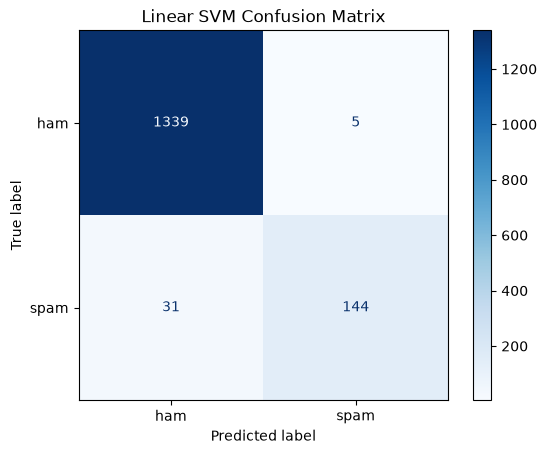

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=best_svm.classes_)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_svm.classes_
)

disp.plot(cmap='Blues')
plt.title("Linear SVM Confusion Matrix")
plt.show()

In [12]:
joblib.dump(best_svm, '../models/linear_svm.pkl')

print("Linear SVM model saved successfully.")

Linear SVM model saved successfully.
